<a href="https://colab.research.google.com/github/wonjun605/Digital-Image-Processing/blob/main/ch04_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [15]:
def threshold_update(img, binImg, T):
  sum1 = np.int32(0)
  sum2 = np.int32(0)
  count1 = 1
  count2 = 1
  for i in range(img.shape[0]):
    for j in range(img.shape[1]):
      if binImg[i][j] == 0:
        sum1 += img[i][j]
        count1 += 1
      else:
        sum2 += img[i][j]
        count2 += 1

    avg1 = sum1/count1
    avg2 = sum2/count2

    T2 = np.int32(avg1 + avg2)/2
    return T2

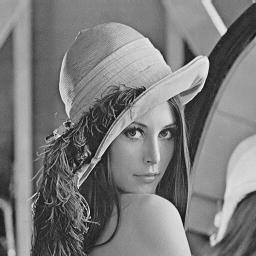

In [22]:
import cv2
from google.colab.patches import cv2_imshow

# 이미지 불러오기 및 RGB 변환
img = cv2.imread('/content/gdrive/My Drive/ColabIP26/Images/lena256.jpg')
RGB_Img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 그레이스케일로 변환
gImg1 = cv2.cvtColor(RGB_Img, cv2.COLOR_RGB2GRAY)

# 변환된 그레이 이미지 출력
cv2_imshow(gImg1)

In [12]:
T1 = 128
T2 = 0
binImg = np.zeros(gImg1.shape, dtype=np.uint8)

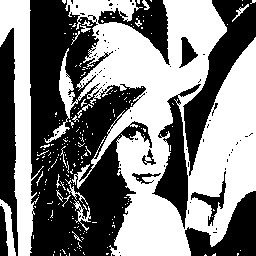

In [13]:
for i in range(gImg1.shape[0]):
  for j in range(gImg1.shape[1]):
    if gImg1[i][j] > T1:
      binImg[i][j] = 255
    else:
      binImg[i][j] = 0
cv2_imshow(binImg)

In [24]:
while True:
  T2 = threshold_update(gImg1, binImg, T1)
  if (np.abs(T1-T2) < 1):
    for i in range(gImg1.shape[0]):
      for j in range(gImg1.shape[1]):
        if gImg1[i][j] > T2:
          binImg[i][j] = 255
        else:
          binImg[i][j] = 0
    break
  else:
    T1 = T2
    for i in range(gImg1.shape[0]):
      for j in range(gImg1.shape[1]):
        if gImg1[i][j] > T1:
          binImg[i][j] = 255
        else:
          binImg[i][j] = 0

In [28]:
print(T1)

141.5
